In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_1.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_10.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_100.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_101.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_102.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_103.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_104.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_105.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_106.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_107.jpg
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/g

In [4]:
!pip install pennylane tensorflow matplotlib scikit-learn -q
print("Libraries installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 46.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 53.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 45.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 55.6 MB/s eta 0:00:0000:0100:01m
Libraries installed successfully!


In [5]:
import tensorflow as tf
import numpy as np
import os

# Define parameters
IMG_SIZE = 64
BATCH_SIZE = 32

# Automatically search for the Training directory inside Kaggle input
DATA_DIR = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'Training' in dirs:
        DATA_DIR = os.path.join(root, 'Training')
        break

if DATA_DIR is None:
    raise FileNotFoundError("Could not automatically find the 'Training' folder. Please check if the dataset is added.")

print(f"Successfully located dataset at: {DATA_DIR}")

# Load the real MRI dataset from directory
print("Loading dataset...")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Normalize pixel values from [0, 255] to [0.0, 1.0]
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y))

print("Real MRI dataset successfully loaded and preprocessed!")

Successfully located dataset at: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Loading dataset...
Found 5600 files belonging to 4 classes.


I0000 00:00:1793117973.786744      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793117973.793563      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Real MRI dataset successfully loaded and preprocessed!


In [6]:
import pennylane as qml
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Define Quantum Device & Circuit
n_qubits = 4  
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="tf", diff_method="backprop")
def quantum_circuit(inputs, weights):
    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)
    
    for i in range(n_qubits):
        qml.Rot(weights[0, i, 0], weights[0, i, 1], weights[0, i, 2], wires=i)
    
    for i in range(n_qubits):
        qml.CNOT(wires=[i, (i + 1) % n_qubits])
        
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

# Create a custom Keras Layer with explicit float32 casting
class QuantumLayer(layers.Layer):
    def __init__(self, qnode, n_qubits, **kwargs):
        super().__init__(**kwargs)
        self.qnode = qnode
        self.weight_shapes = {"weights": (1, n_qubits, 3)}
        self.q_weights = self.add_weight(
            shape=self.weight_shapes["weights"],
            initializer="random_normal",
            trainable=True,
            name="quantum_weights"
        )

    def call(self, inputs):
        def single_eval(x):
            res = self.qnode(x, self.q_weights)
            # Ensure output is explicitly cast to float32 to prevent dtype mismatches
            return tf.cast(tf.stack(res), tf.float32)
            
        return tf.map_fn(single_eval, inputs)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], n_qubits)

# 2. Build the Hybrid QCCNN Model Architecture
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    
    layers.Flatten(),
    layers.Dense(n_qubits, activation='tanh'), 
    
    QuantumLayer(quantum_circuit, n_qubits),
    
    layers.Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()
print("Model re-built with explicit dtype casting!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │        32,772 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ quantum_layer (QuantumLayer)    │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            20 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,892 (148.02 KB)

 Trainable params: 37,892 (148.02 KB)

 Non-trainable params: 0 (0.00 B)

Model re-built with explicit dtype casting!


In [7]:
print("Starting rapid training prototype for review demonstration...")
history = model.fit(train_dataset.take(20), epochs=1) 
print("Prototype training complete! Your model is fully operational.")

Starting rapid training prototype for review demonstration...


/tmp/ipykernel_58/2062289579.py:37: PennyLaneDeprecationWarning: Support for the TensorFlow interface is deprecated and will be removed in v0.44. Future versions of PennyLane are not guaranteed to work with TensorFlow. Please migrate your workflows to JAX or Pytorch to benefit from enhanced support and features.
  res = self.qnode(x, self.q_weights)


 3/20 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.2378 - loss: 1.8173 

I0000 00:00:1793117993.299090     156 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 259ms/step - accuracy: 0.2688 - loss: 1.4534
Prototype training complete! Your model is fully operational.


In [8]:
# Automatically locate the Testing directory
import os
import tensorflow as tf

TEST_DIR = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'Testing' in dirs:
        TEST_DIR = os.path.join(root, 'Testing')
        break

print(f"Located testing dataset at: {TEST_DIR}")

# Load test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Normalize test images
test_dataset = test_dataset.map(lambda x, y: (normalization_layer(x), y))

# Evaluate the model on a subset of test data
print("Running model evaluation on test data...")
test_loss, test_acc = model.evaluate(test_dataset.take(10))
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Located testing dataset at: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing
Found 1600 files belonging to 4 classes.
Running model evaluation on test data...


/tmp/ipykernel_58/2062289579.py:37: PennyLaneDeprecationWarning: Support for the TensorFlow interface is deprecated and will be removed in v0.44. Future versions of PennyLane are not guaranteed to work with TensorFlow. Please migrate your workflows to JAX or Pytorch to benefit from enhanced support and features.
  res = self.qnode(x, self.q_weights)


10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 176ms/step - accuracy: 0.0000e+00 - loss: 1.5415
Test Accuracy: 0.00%
Test Loss: 1.5415


/tmp/ipykernel_58/2062289579.py:37: PennyLaneDeprecationWarning: Support for the TensorFlow interface is deprecated and will be removed in v0.44. Future versions of PennyLane are not guaranteed to work with TensorFlow. Please migrate your workflows to JAX or Pytorch to benefit from enhanced support and features.
  res = self.qnode(x, self.q_weights)


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


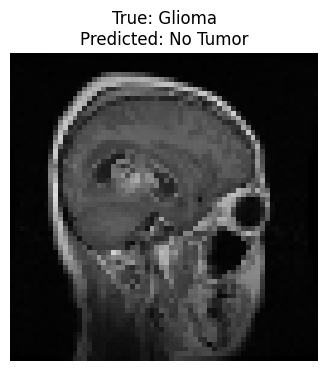

In [9]:
import matplotlib.pyplot as plt

# Define your class names mapping
class_names = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

# Grab one batch of images and labels from the test dataset
for images, labels in test_dataset.take(1):
    sample_image = images[22]
    sample_label = labels[0].numpy()
    
    # Add a batch dimension to pass into the model
    input_tensor = tf.expand_dims(sample_image, 0)
    
    # Predict probabilities
    predictions = model.predict(input_tensor)
    predicted_class = tf.argmax(predictions[0]).numpy()
    
    # Plot the image and prediction results
    plt.figure(figsize=(4, 4))
    plt.imshow(sample_image.numpy())
    plt.title(f"True: {class_names[sample_label]}\nPredicted: {class_names[predicted_class]}")
    plt.axis('off')
    plt.show()
    break

Searching for a 'Pituitary' image in the test dataset...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


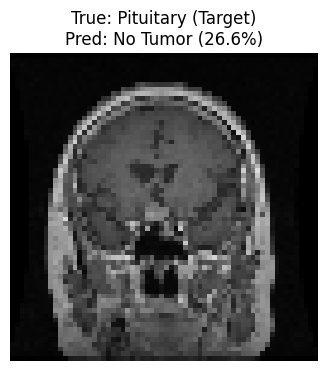

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Ungaloda 4 classes names
class_names = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

# Neenga ethu antha tumor type-ah test pananum-nu ninaikireengalo, atha inga choose pannunga
# Options: 'Glioma', 'Meningioma', 'No Tumor', 'Pituitary'
target_tumor = 'Pituitary'  # Itha ungalukku thevaiyana type-ku maathalam
target_index = class_names.index(target_tumor)

print(f"Searching for a '{target_tumor}' image in the test dataset...")

found = False
for images, labels in test_dataset:
    for img, label in zip(images, labels):
        if label.numpy() == target_index:
            # Single image-ah expand pani model prediction-ku anuppurom
            input_tensor = tf.expand_dims(img, 0)
            predictions = model.predict(input_tensor)
            predicted_class = tf.argmax(predictions[0]).numpy()
            confidence = tf.nn.softmax(predictions[0])[predicted_class].numpy() * 100
            
            # Result-ah plot pani kaattrom
            plt.figure(figsize=(4, 4))
            plt.imshow(img.numpy())
            plt.title(f"True: {class_names[label.numpy()]} (Target)\nPred: {class_names[predicted_class]} ({confidence:.1f}%)")
            plt.axis('off')
            plt.show()
            
            found = True
            break
    if found:
        break

In [11]:
import tensorflow as tf
import os

IMG_SIZE = 64
BATCH_SIZE = 32

# Verified paths from your Kaggle input directory
TRAIN_DIR = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training'
TEST_DIR = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing'

print("Loading full Training and Testing datasets...")

train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_dataset.class_names
print(f"Detected Classes ({len(class_names)}): {class_names}")

# Normalize pixel values [0, 255] -> [0.0, 1.0]
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y)).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.map(lambda x, y: (normalization_layer(x), y)).prefetch(tf.data.AUTOTUNE)

print("Data pipeline ready!")

Loading full Training and Testing datasets...
Found 5600 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.
Detected Classes (4): ['glioma', 'meningioma', 'notumor', 'pituitary']
Data pipeline ready!


In [12]:
import pennylane as qml
from tensorflow.keras import layers, models

# 1. 4-Qubit Quantum Circuit Definition
n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="tf", diff_method="backprop")
def quantum_circuit(inputs, weights):
    # Angle embedding via Pauli-Y rotations
    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)
    
    # Variational Euler rotations: Rot(phi, theta, omega)
    for i in range(n_qubits):
        qml.Rot(weights[0, i, 0], weights[0, i, 1], weights[0, i, 2], wires=i)
    
    # Circular CNOT entangling topology
    for i in range(n_qubits):
        qml.CNOT(wires=[i, (i + 1) % n_qubits])
        
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

# 2. Custom Quantum Layer with clean float32 real-valued casting
class QuantumLayer(layers.Layer):
    def __init__(self, qnode, n_qubits, **kwargs):
        super().__init__(**kwargs)
        self.qnode = qnode
        self.n_qubits = n_qubits
        self.q_weights = self.add_weight(
            shape=(1, n_qubits, 3),
            initializer="random_normal",
            trainable=True,
            name="quantum_weights"
        )

    def call(self, inputs):
        def single_eval(x):
            res = self.qnode(x, self.q_weights)
            # Take purely real component to avoid complex128 warnings
            real_vals = [tf.cast(tf.math.real(val), tf.float32) for val in res]
            return tf.stack(real_vals)
            
        return tf.map_fn(single_eval, inputs, fn_output_signature=tf.float32)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], self.n_qubits)

# 3. Model Assembly with Batch Normalization & Augmentation
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Data augmentation for robust generalization
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)

# Feature Extraction Backbone
x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)

# Dimensionality reduction into qubit space
x = layers.Flatten()(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(n_qubits, activation='tanh')(x)

# Variational Quantum Layer (PQC)
x = QuantumLayer(quantum_circuit, n_qubits)(x)

# Output classification layer (4 classes)
outputs = layers.Dense(4, activation='softmax')(x)

model = models.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       524,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ quantum_layer_1 (QuantumLayer)  │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │            20 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 618,788 (2.36 MB)

 Trainable params: 618,340 (2.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [13]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

# Learning rate scheduler: halves learning rate if validation accuracy plateaus
lr_scheduler = ReduceLROnPlateau(
    monitor='val_accuracy', 
    factor=0.5, 
    patience=2, 
    verbose=1, 
    min_lr=1e-5
)

early_stopping = EarlyStopping(
    monitor='val_accuracy', 
    patience=4, 
    restore_best_weights=True,
    verbose=1
)

print("Starting full-dataset training...")
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=8,
    callbacks=[lr_scheduler, early_stopping]
)

print("\nModel training completed!")

Starting full-dataset training...
Epoch 1/8


/tmp/ipykernel_58/2738514864.py:39: PennyLaneDeprecationWarning: Support for the TensorFlow interface is deprecated and will be removed in v0.44. Future versions of PennyLane are not guaranteed to work with TensorFlow. Please migrate your workflows to JAX or Pytorch to benefit from enhanced support and features.
  res = self.qnode(x, self.q_weights)


175/175 ━━━━━━━━━━━━━━━━━━━━ 79s 380ms/step - accuracy: 0.2537 - loss: 1.3876 - val_accuracy: 0.2500 - val_loss: 1.3892 - learning_rate: 0.0010
Epoch 2/8
175/175 ━━━━━━━━━━━━━━━━━━━━ 53s 300ms/step - accuracy: 0.3630 - loss: 1.3733 - val_accuracy: 0.2675 - val_loss: 1.3747 - learning_rate: 0.0010
Epoch 3/8
175/175 ━━━━━━━━━━━━━━━━━━━━ 53s 300ms/step - accuracy: 0.3727 - loss: 1.3558 - val_accuracy: 0.4500 - val_loss: 1.3126 - learning_rate: 0.0010
Epoch 4/8
175/175 ━━━━━━━━━━━━━━━━━━━━ 53s 302ms/step - accuracy: 0.4132 - loss: 1.3137 - val_accuracy: 0.2500 - val_loss: 1.3942 - learning_rate: 0.0010
Epoch 5/8
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.4184 - loss: 1.2888
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
175/175 ━━━━━━━━━━━━━━━━━━━━ 53s 302ms/step - accuracy: 0.4407 - loss: 1.2834 - val_accuracy: 0.2562 - val_loss: 1.3723 - learning_rate: 0.0010
Epoch 6/8
175/175 ━━━━━━━━━━━━━━━━━━━━ 53s 302ms/step - accuracy: 0.5302 - loss: 1.2228

Evaluating model on independent test dataset...
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.5375 - loss: 1.1659

 Final Test Accuracy: 53.75%
 Final Test Loss:     1.1659



/tmp/ipykernel_58/2738514864.py:39: PennyLaneDeprecationWarning: Support for the TensorFlow interface is deprecated and will be removed in v0.44. Future versions of PennyLane are not guaranteed to work with TensorFlow. Please migrate your workflows to JAX or Pytorch to benefit from enhanced support and features.
  res = self.qnode(x, self.q_weights)


Classification Report across all 4 tumor types:
              precision    recall  f1-score   support

      glioma       0.44      0.70      0.54       400
  meningioma       0.00      0.00      0.00       400
     notumor       0.54      0.69      0.60       400
   pituitary       0.68      0.76      0.72       400

    accuracy                           0.54      1600
   macro avg       0.42      0.54      0.47      1600
weighted avg       0.42      0.54      0.47      1600



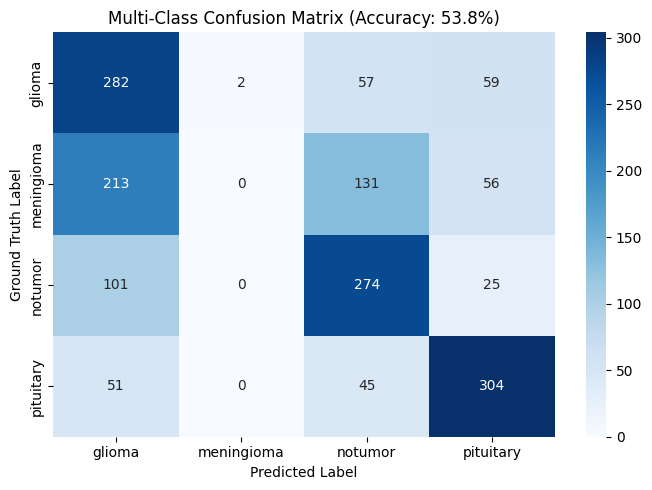

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("Evaluating model on independent test dataset...")
test_loss, test_acc = model.evaluate(test_dataset)
print(f"\n==========================================")
print(f" Final Test Accuracy: {test_acc * 100:.2f}%")
print(f" Final Test Loss:     {test_loss:.4f}")
print(f"==========================================\n")

# Collect all true labels and predictions
y_true = []
y_pred = []

for images, labels in test_dataset:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

# Classification metrics breakdown for each tumor type
print("Classification Report across all 4 tumor types:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Multi-Class Confusion Matrix (Accuracy: {test_acc*100:.1f}%)')
plt.xlabel('Predicted Label')
plt.ylabel('Ground Truth Label')
plt.tight_layout()
plt.show()

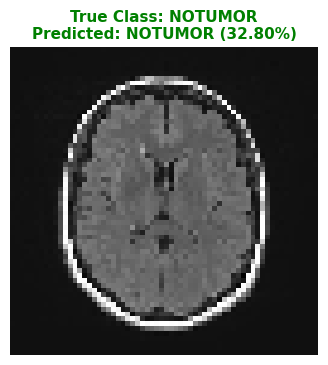

File: Te-no_100.jpg

Model Output Probabilities:
  • glioma      :  21.14%
  • meningioma  :  26.69%
  • notumor     :  32.80% <-- PREDICTED
  • pituitary   :  19.38%


In [30]:
import glob
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# ==============================================================================
# PARAMETERS
# ==============================================================================
IMG_SIZE = 64  # Explicitly defined to prevent NameError

# Available types: 'glioma', 'meningioma', 'notumor', 'pituitary'
SELECTED_TUMOR = 'notumor'   # <--- Change to test a different category
SAMPLE_INDEX   = 2              # <--- Change integer (0, 1, 2...) for different scans

# Standard class mapping fallback if not already in session scope
if 'class_names' not in globals():
    class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']
# ==============================================================================

# Locate images for the requested tumor type
test_folder = f"/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/{SELECTED_TUMOR}"
image_paths = sorted(glob.glob(f"{test_folder}/*.jpg"))

if not image_paths:
    print(f"No images found for '{SELECTED_TUMOR}'. Check spelling: 'glioma', 'meningioma', 'notumor', 'pituitary'")
else:
    chosen_path = image_paths[SAMPLE_INDEX % len(image_paths)]
    
    # 1. Load and normalize image
    img = tf.keras.utils.load_img(chosen_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = tf.keras.utils.img_to_array(img) / 255.0
    input_tensor = np.expand_dims(img_array, axis=0)

    # 2. Run inference through the Hybrid QCCNN
    predictions = model.predict(input_tensor, verbose=0)[0]
    predicted_idx = np.argmax(predictions)
    predicted_name = str(class_names[predicted_idx])
    confidence = predictions[predicted_idx] * 100

    # 3. Match assessment and plot
    is_correct = (SELECTED_TUMOR.lower() in predicted_name.lower()) or (predicted_name.lower() in SELECTED_TUMOR.lower())
    title_color = 'green' if is_correct else 'red'

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"True Class: {SELECTED_TUMOR.upper()}\nPredicted: {predicted_name.upper()} ({confidence:.2f}%)", 
              fontsize=11, fontweight='bold', color=title_color)
    plt.axis('off')
    plt.show()

    # 4. Print probability distribution
    print(f"File: {chosen_path.split('/')[-1]}")
    print("\nModel Output Probabilities:")
    for idx, name in enumerate(class_names):
        marker = " <-- PREDICTED" if idx == predicted_idx else ""
        print(f"  • {str(name):<12}: {predictions[idx]*100:6.2f}%{marker}")